In [1]:
#LA API QUE SE REGISTRO SON LOS DATOS BASICOS DE LOS JUGADORES PARTICIPANTES
import requests
import pandas as pd

#SE HACE EL LLAMADO DE LA API DESDE UN APARTADO "SEGURO" COMO LO ES ESPN
base_url = "https://site.api.espn.com"
endpoint = "/apis/site/v2/sports/golf/pga/scoreboard?dates=20260830"
response = requests.get(base_url + endpoint)
print(response.status_code) # rectificamos que la aprobacion de la api fue la correcta 
data = response.json() # Convertimos la lectura a JSON para poder emepzar a interpretar 

print(data.keys()) # Miramos todo lo relacionado a lo que contiene el dataset

# ====================== EVENTO ======================================
#NOS ASEGURAMOS DEL TORNEO TRATADO - ESTE TORNEO TIENE BUENAS METRICAS Y OCURRIO HACE POCO
assert data["events"], "No hay eventos disponibles en la API en este momento" # Nos aseguramos de que haya al menos un torneo antes de indexar
evento = data["events"][0] # Ingreso al primer evento que se registro
print(evento["name"])# Tengo el nombre del evento
evento_id = evento["id"]
print("ID del torneo:", evento_id)
competicion = evento["competitions"][0]
print(competicion.keys()) #Miramos las llaves que posee para asi hacer los llamados correspondientes 
jugador = competicion["competitors"]

# ================== CREACION DATAFRAME ============================
datos = []

for jugadores in jugador:

    nombre = jugadores["athlete"]["displayName"]

    # Score acumulado del jugador
    score = jugadores.get("score")

    # Posición
    posicion = jugadores.get("order")

    # Resultados por ronda
    linescores = jugadores.get("linescores", [])

    #Temporada
    season = evento["season"]["year"]

    ronda1 = linescores[0].get("value") if len(linescores) > 0 else None
    ronda2 = linescores[1].get("value") if len(linescores) > 1 else None
    ronda3 = linescores[2].get("value") if len(linescores) > 2 else None
    ronda4 = linescores[3].get("value") if len(linescores) > 3 else None


    datos.append(
        {
            "jugador": nombre,
            "posicion": posicion,
            "score": score,
            "ronda1": ronda1,
            "ronda2": ronda2,
            "ronda3": ronda3,
            "ronda4": ronda4,
            "Temporada" :season,
        }
    )

df = pd.DataFrame(datos)
df['score'] = df['score'].str.replace('E', '0')
df['ronda4'] = df['ronda4'].fillna(0)
df['ronda3'] = df['ronda3'].fillna(0)
df['ronda2'] = df['ronda2'].fillna(0)
df['ronda1'] = df['ronda1'].fillna(0)
df['ronda3'] = df['ronda3'].astype(int)
df['ronda2'] = df['ronda2'].astype(int)
df['ronda1'] = df['ronda1'].astype(int)
df['ronda4'] = df['ronda4'].astype(int)
df['score'] = df['score'].astype(int)
df 

df.to_csv("TOUR CHAMPIONCHIP_respaldo.csv", index=False)

200
dict_keys(['leagues', 'season', 'day', 'events', 'provider'])
TOUR Championship
ID del torneo: 401811964
dict_keys(['id', 'uid', 'date', 'endDate', 'timeValid', 'neutralSite', 'conferenceCompetition', 'playByPlayAvailable', 'recent', 'competitors', 'status', 'broadcasts', 'startDate', 'broadcast', 'geoBroadcasts', 'highlights'])


In [2]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

col__pga = [
    "posicion",
    "score",
    "ronda1",
    "ronda2",
    "ronda3",
    "ronda4",
]

data_pga = df[col__pga].copy()
print(data_pga.head())


scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_pga)
display(data_scaled)

pd.DataFrame(data_scaled,columns=data_pga.columns)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca

   posicion  score  ronda1  ronda2  ronda3  ronda4
0         1    -16      65      67      66      66
1         2    -13      64      66      65      72
2         3    -12      65      65      66      72
3         4    -11      68      68      67      66
4         5    -11      68      67      66      68


array([[-1.67524673e+00, -1.84972107e+00, -2.47891560e-02,
         9.35063764e-02,  7.86751914e-02, -1.34968904e-01],
       [-1.55971247e+00, -1.19687834e+00, -1.48734936e-01,
         1.33580538e-02, -2.71293764e-03,  3.32231149e-01],
       [-1.44417822e+00, -9.79264096e-01, -2.47891560e-02,
        -6.67902688e-02,  7.86751914e-02,  3.32231149e-01],
       [-1.32864396e+00, -7.61649852e-01,  3.47048183e-01,
         1.73654699e-01,  1.60063321e-01, -1.34968904e-01],
       [-1.21310970e+00, -7.61649852e-01,  3.47048183e-01,
         9.35063764e-02,  7.86751914e-02,  2.07644468e-02],
       [-1.09757545e+00, -7.61649852e-01, -3.96626495e-01,
         5.74396312e-01,  7.86751914e-02,  2.07644468e-02],
       [-9.82041188e-01, -7.61649852e-01,  5.94939743e-01,
        -6.67902688e-02,  7.86751914e-02,  2.07644468e-02],
       [-8.66506930e-01, -7.61649852e-01,  3.47048183e-01,
         2.53803022e-01, -1.65489196e-01,  9.86311224e-02],
       [-7.50972673e-01, -7.61649852e-01, -2.478

array([[  0.89690381,  -2.32364925],
       [  0.76886679,  -1.78549876],
       [  0.74026914,  -1.54834709],
       [  0.76073335,  -1.31619642],
       [  0.73236175,  -1.23166549],
       [  0.58492223,  -1.18787556],
       [  0.72313392,  -1.05904538],
       [  0.65412574,  -0.99236403],
       [  0.5663507 ,  -0.92179195],
       [  0.52213449,  -0.8447878 ],
       [  0.51884102,  -0.61441625],
       [  0.57191331,  -0.49988713],
       [  0.46072206,  -0.44249611],
       [  0.44098147,  -0.2210727 ],
       [  0.41381489,  -0.13369906],
       [  0.32999639,  -0.06600082],
       [  0.40140377,   0.03751526],
       [  0.25058991,   0.39796416],
       [  0.28145101,   0.50215492],
       [  0.21304534,   0.57025763],
       [  0.20419352,   0.95898201],
       [  0.1593748 ,   1.03456481],
       [  0.10922379,   1.11587971],
       [  0.06363183,   1.19574213],
       [  0.07458115,   1.58911946],
       [ -0.0609353 ,   1.80875403],
       [ -0.08617892,   2.04161052],
 

In [3]:
pca.explained_variance_ratio_

array([0.69935019, 0.27074262])

In [4]:
pca.components_

array([[-0.21653814, -0.28531976,  0.46719668,  0.46792495,  0.46819986,
         0.46396796],
       [ 0.69447584,  0.62607871,  0.15531728,  0.16440292,  0.17936239,
         0.20592746]])

Text(0, 0.5, 'Componente principal 2')

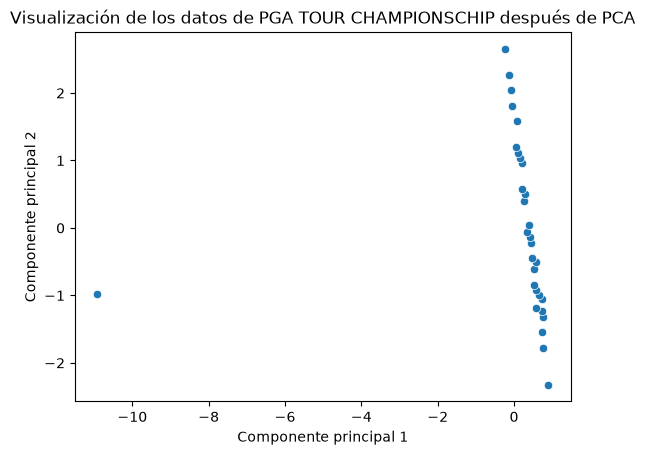

In [5]:
import seaborn as sns
sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1])
plt.title("Visualización de los datos de PGA TOUR CHAMPIONSCHIP después de PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

Text(0, 0.5, 'Componente principal 2')

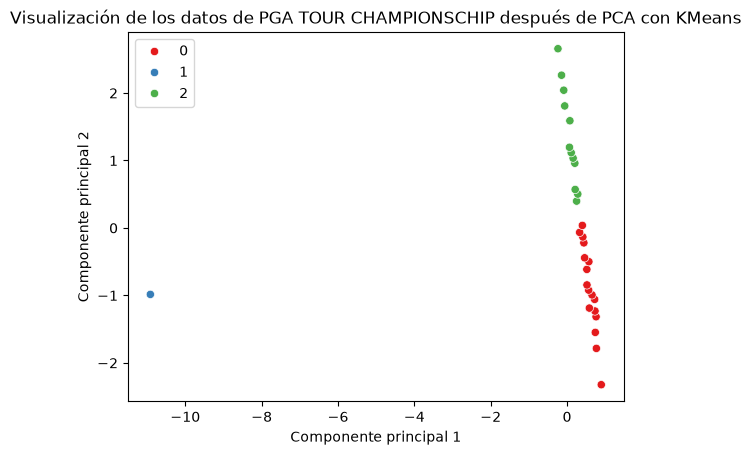

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set1')
plt.title("Visualización de los datos de PGA TOUR CHAMPIONSCHIP después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

In [7]:
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 1], dtype=int32)

In [8]:
data_clusters = pd.concat(
    [data_pga.reset_index(drop=True), pd.DataFrame(kmeans.labels_, columns=["Cluster"])],
    axis=1
)

display(data_clusters.head(50))

,posicion,score,ronda1,ronda2,ronda3,ronda4,Cluster
0,1,-16,65,67,66,66,0
1,2,-13,64,66,65,72,0
2,3,-12,65,65,66,72,0
3,4,-11,68,68,67,66,0
4,5,-11,68,67,66,68,0
5,6,-11,62,73,66,68,0
6,7,-11,70,65,66,68,0
7,8,-11,68,69,63,69,0
8,9,-11,65,68,65,71,0
9,10,-11,64,67,67,71,0


In [9]:
data_clusters.dtypes

data_clusters['score'] = data_clusters['score'].astype(float)

data_clusters.dtypes

posicion      int64
score       float64
ronda1        int64
ronda2        int64
ronda3        int64
ronda4        int64
Cluster       int32
dtype: object

In [10]:
data_clusters.groupby('Cluster').mean()

,posicion,score,ronda1,ronda2,ronda3,ronda4
Cluster,,,,,,
0,9.0,-10.823529,66.352941,67.529412,66.411765,68.882353
1,30.0,4.000000,23.000000,0.000000,0.000000,0.000000
2,23.5,-3.750000,67.083333,68.916667,68.500000,71.750000


<Axes: ylabel='Cluster'>

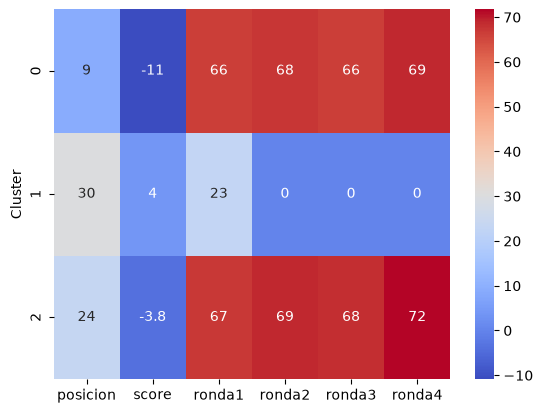

In [11]:
sns.heatmap(data_clusters.groupby('Cluster').mean(), annot=True, cmap='coolwarm')

In [12]:
data_clusters.to_csv("TOUR_CHAMPIONSHIP.csv", index=False)